In [1]:
import noise_channels
import numpy as np
import qiskit as qk
from qiskit.quantum_info import Operator
import lpdo_utils
import quimb.tensor as qtn
from functools import reduce

def single_qubit_layer_kraus(params, lpdo_shapes = True):
    """
    Unitary defined as with qiskit's definition of a general u gate:
    U(p0 = \theta, p1 = \phi, p2 = \lambda) = [cos(p0/2)        , -e^{i*p3} sin(p0/2)   ]
                                              [e^{i\p1}sin(p0/2), +e^{i(p1+p3)}cos(p0) ]
    """
    if isinstance(params, list):
        params = np.array(params)

    if params.shape[1] != 3:
        raise ValueError(f"Must specify 3 parameters per qubit, got instead {params.shape}.")

    num_qubits = params.shape[0]

    single_qubit_unitary = lambda p: np.array([[np.cos(p[0] / 2),  -1 * np.exp(1j * p[2]) * np.sin(p[0] / 2)],
                                               [np.exp(1j * p[1]) * np.sin(p[0] / 2), np.exp(1j * (p[1] + p[2])) * np.cos(p[0] / 2)]])
    
    single_qubit_gates = [single_qubit_unitary(p) for p in params]
    
    for n, op in enumerate(single_qubit_gates):
        if (n == 0) or (n == num_qubits - 1):
            single_qubit_gates[n] = op.reshape(1, 1, 2, 2)
        else:
            single_qubit_gates[n] = op.reshape(1, 1, 1, 2, 2)

    return single_qubit_gates

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


In [13]:
lpdo = noise_channels.select_noise_channel('ext_gen_dict_bigger_231106_nazca_50q', 4, tensor_type='lpdo')
mpo = noise_channels.select_noise_channel('ext_gen_dict_bigger_231106_nazca_50q', 4, tensor_type='mpo')
lpdo_utils.lpdo_to_mpo(lpdo).distance(mpo)

3.349494945048936e-15

In [ ]:
num_qubits = 5
rho = reduce(np.kron, [np.array([[1,0],[0,0]])] * num_qubits)

params = np.random.rand(num_qubits, 3)
sq_layer = single_qubit_layer_kraus(params)
u = lpdo_utils.build_lpdo(tn_data=sq_layer)

qc = qk.QuantumCircuit(num_qubits)
for q, p in enumerate(params):
    qc.u(*p, q)

qc.draw()

state_label = [3,1,0,4,4]
povm_label = [3,3,3,1,0]

tn = lpdo_utils.process_tn(u, state_label=state_label, povm_label=povm_label)[0]
qis = lpdo_utils.transition_prob_qiskit(qc, state_label = list(map(str, state_label)), povm_label=list(map(str, povm_label)))
print(tn.contract() - qis, tn.contract(), qis)

In [ ]:
a = np.eye(4)

[a[i][j] := 3 for i in range(1,4)]

In [ ]:
params == 

In [ ]:
state_label = [0,]*num_qubits
povm_label = [0,]*num_qubits

tn = lpdo_utils.process_tn(u, state_label=state_label, povm_label=povm_label)[0]
qis = lpdo_utils.transition_prob_qiskit(qc, state_label = list(map(str, state_label)), povm_label=list(map(str, povm_label)))
print(tn.contract() - qis)

In [ ]:
list(map(str, state_label))

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

std = 1 / np.sqrt(2)
M = 10_000

A = np.random.normal(0, std, (M, 2, 2)) + 1j * np.random.normal(0, std, (M, 2, 2))

x = np.array([np.trace(a @ np.conj(a).T) for a in A])
print(x.mean())
print(x.var())

plt.hist(x.real, bins = 100);

In [ ]:
def parameterised_unitary(params):
    """
    Parameterisation of unitary in Eq. (19) in http://home.lu.lv/~sd20008/papers/essays/Random%20unitary%20[paper].pdf.

    To generate a random unitary, sample:
        params[1], params[2] ~ Unif[0, 2\pi] 
        params[0] = arcsin(sqrt(x)) with x ~ Unif[0,1].
    """

    u = np.array([[+np.exp(+1j * params[1]) * np.cos(params[0]), +np.exp(+1j * params[2]) * np.sin(params[0])],
                  [-np.exp(-1j * params[2]) * np.sin(params[0]), +np.exp(-1j * params[1]) * np.cos(params[0])]])
    return u

def single_qubit_coherent_error(params):
    """
    Creates the PTM for a single-qubit unitary map.
    """

    pauli_matrices = [[[1.,0.],   [0.,1.]],
                      [[0.,1.],   [1.,0.]],
                      [[0.,-1.j], [1.j,0.]],
                      [[1.,0.],   [0.,-1.]]]

    single_qubit_ptms = []

    for p in params:
        
        ptm = np.eye(4)
        u1 = parameterised_unitary(p)
        
        for i in range(1, 4):
            for j in range(1, 4):
                ptm[i, j] = 0.5 * np.real(np.trace(np.dot(pauli_matrices[i], np.dot(u1, np.dot(pauli_matrices[j], np.conjugate(u1.T))))))

        single_qubit_ptms.append(ptm)
    
    return single_qubit_ptms, qtn.MPO_product_operator(single_qubit_ptms)

m = 20
eps = 1e-3
params = np.array([np.arcsin(np.sqrt(eps * np.random.rand(m))), 
                   eps * 2 * np.pi * np.random.rand(m), 
                   2 * np.pi * np.random.rand(m)]).T

single_qubit_coherent_error(params)

In [ ]:
params

In [ ]:


p0 = np.array([[1,0],[0,0]])

unitaries = [unitary_parameterization(p) for p in params]

X = np.array([[0,1],[1,0]])
Y = np.array([[0,-1j],[1j,0]])
Z = np.array([[1,0],[0,-1]])
H = np.array([[1,1],[-1,1]]) / np.sqrt(2)

rhos = [u @ p0 @ np.conj(u).T for u in unitaries]

pauli = np.array([X, Y, Z])

bv = lambda r: np.real(np.array([np.trace(X @ r), np.trace(Y @ r), np.trace(Z @ r)]))

bloch_vectors = np.array([bv(r) for r in rhos])
xx, yy, zz = bloch_vectors.T

In [ ]:
import matplotlib.pyplot as plt
from matplotlib import cm, colors
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

# Create a sphere
r = 1
pi = np.pi
cos = np.cos
sin = np.sin
phi, theta = np.mgrid[0.0:pi:100j, 0.0:2.0*pi:100j]
x = r*sin(phi)*cos(theta)
y = r*sin(phi)*sin(theta)
z = r*cos(phi)

#Set colours and render
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

ax.plot_surface(x, y, z,  rstride=1, cstride=1, color='c', alpha=0.2, linewidth=0)

ax.scatter(xx, yy, zz, color="k",s=20)

ax.set_xlim([-1,1])
ax.set_ylim([-1,1])
ax.set_zlim([-1,1])
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

In [ ]:
import noise_channels
import lpdo_utils

mpo = noise_channels.select_noise_channel('even_depol1_odd_depol05', 5, tensor_type='mpo')
lpdo = noise_channels.select_noise_channel('even_depol1_odd_depol05', 5, tensor_type='lpdo')
lpdo_utils.lpdo_to_mpo(lpdo).distance(mpo)

In [ ]:
import numpy as np
d1 = np.array([np.squeeze(t) for t in (lpdo_utils.lpdo_to_mpo(lpdo).compress_all_()).arrays])
d1

In [ ]:
d2 = np.array([np.squeeze(d) for d in mpo.compress_all_().arrays])
np.isclose(d1, d2)

In [ ]:
import numpy as np
num_qubits = 5
params = np.array([[3.00547398e-02, 7.77730907e-05, 6.17814209e+00],
                   [2.76584025e-02, 6.30579886e-04, 5.81529206e+00],
                   [1.88957563e-02, 3.03815219e-03, 5.74209201e+00],
                   [1.70521901e-02, 2.14975744e-03, 4.46061858e+00],
                   [2.85241333e-02, 4.85965411e-03, 4.95735706e+00],
                   [1.48751794e-02, 9.23733394e-04, 2.75367387e+00],
                   [2.94347273e-02, 4.10139006e-03, 6.18168685e+00],
                   [1.92935976e-02, 5.21046056e-03, 2.40779110e+00],
                   [2.52159703e-02, 2.14070019e-03, 3.03112384e+00],
                   [2.54789185e-02, 7.76826973e-04, 3.81226679e+00],
                   [1.04998210e-02, 4.68402509e-03, 1.15964766e+00],
                   [2.28560583e-02, 1.51864557e-03, 4.86718301e+00],
                   [2.54664840e-02, 2.08769462e-03, 3.94273381e+00],
                   [2.47447250e-02, 1.08457883e-03, 2.52471461e+00],
                   [1.77580516e-02, 3.51123833e-03, 4.68656960e+00],
                   [1.74055805e-02, 4.83659666e-03, 1.91857332e+00],
                   [2.70344347e-02, 1.94396868e-04, 4.03463346e+00],
                   [3.52914278e-03, 7.51015669e-04, 4.22965886e+00],
                   [3.06779071e-02, 4.50731593e-03, 2.83864261e+00],
                   [1.11295405e-02, 6.20680458e-03, 3.21719165e+00]])[:num_qubits]

np.array([parameterised_unitary(p) for p in params])

In [ ]:
np.array(single_qubit_coherent_error(params)[0]).round(5)

In [ ]:
print(mpo.compress_all_().arrays[0])

In [ ]:
print(np.array(single_qubit_coherent_error(params)[0]))

In [ ]:
np.array(single_qubit_coherent_error(params)[0])[4] - mpo.compress_all_().arrays[4].fl

In [20]:
import json
import numpy as np

In [21]:
num_qubits = 50

fname = 'ext_gen_dict_bigger_231106_nazca_50q'
with open(fname + '.json') as file:
    spl_coeffs = json.load(file)

# Create a list to contain Pauli strings in specific order (first single-qubit temrs in lexicographical order, then two-qubit in lexicographical order)
paulis = np.array([['I',] * num_qubits,] * (3 * num_qubits + 9 * (num_qubits - 1)))

# Create ordered single-qubit terms
for q in range(num_qubits):
    paulis[3 * q + 0][q] = 'X'
    paulis[3 * q + 1][q] = 'Y'
    paulis[3 * q + 2][q] = 'Z'

# Create ordered two-qubit terms
for q in range(num_qubits - 1):
    paulis[3*num_qubits + 9*q + 0][q:q+2] = ['X', 'X']
    paulis[3*num_qubits + 9*q + 1][q:q+2] = ['X', 'Y']
    paulis[3*num_qubits + 9*q + 2][q:q+2] = ['X', 'Z']
    paulis[3*num_qubits + 9*q + 3][q:q+2] = ['Y', 'X']
    paulis[3*num_qubits + 9*q + 4][q:q+2] = ['Y', 'Y']
    paulis[3*num_qubits + 9*q + 5][q:q+2] = ['Y', 'Z']
    paulis[3*num_qubits + 9*q + 6][q:q+2] = ['Z', 'X']
    paulis[3*num_qubits + 9*q + 7][q:q+2] = ['Z', 'Y']
    paulis[3*num_qubits + 9*q + 8][q:q+2] = ['Z', 'Z']

# Join lists to create Pauli strings
paulis = [''.join(p) for p in paulis.tolist()]

max_num_qubits = len(list(spl_coeffs.keys())[0])

# If num_qubits < tot qubits in the SPL dictionary, add identities in the keys to ignore undesired qubits
trivial_qubits = 'I' * (max_num_qubits - num_qubits)

spl_dict = {}
for p_str in paulis: 
    try:
        spl_dict[p_str] = spl_coeffs[p_str + trivial_qubits]
    except KeyError:
        spl_dict[p_str] = 0

spl_values = list(spl_dict.values())

with open(fname + ".txt", "w") as file:
    file.write("pauli,coefficient\n")
    for k, v in spl_dict.items():
        file.write(f"{k},{v}\n")

[0.0006320839, 0.0005200661, 0.0005411299, 0, 0.0020936255, 0, 0, 0, 0.0013654618, 0, 0.0090255188, 0, 0.0006695279, 0, 0.0001095734, 0, 0.0085284285, 0, 0.0007447355, 0, 0, 0.0039846154, 0.0008426945, 0, 0.0034792492, 0.0012322326, 0.0024037935, 0, 0, 0.0008933452, 0.0225000199, 0, 0.0033161667, 8.6554e-06, 0.0016472302, 0, 0.0003780894, 0, 0.0053142074, 0, 5.1623e-05, 0, 5.12642e-05, 0, 0, 0, 0.0012674237, 0, 0.0008061933, 0.001578609, 0, 0.0006830247, 0, 0.0007473844, 0.0009940738, 0, 0.0004813126, 0, 0.0004483246, 0, 0, 0, 0, 0, 0, 0, 0.0113273733, 0, 0.000330867, 0.0006606239, 0, 0.0015293008, 0, 0, 0, 0.0012659751, 0.0009610294, 0, 0.0008428288, 0, 0, 0.0001740723, 0.0005178808, 0, 0.0002491731, 0, 0.0007969036, 0, 0.0043660247, 0, 0, 0.0002076308, 0, 0.0014206321, 0.0002548358, 0, 0.0007031972, 0, 0, 0, 2.50218e-05, 0, 0.0006525601, 0, 0.0008338478, 0, 0.0001138623, 0, 0.0013362162, 0.000318903, 0.000495978, 0, 0.0004880847, 0.0026111509, 4.4488e-06, 0.0002834988, 0.0015891718, 

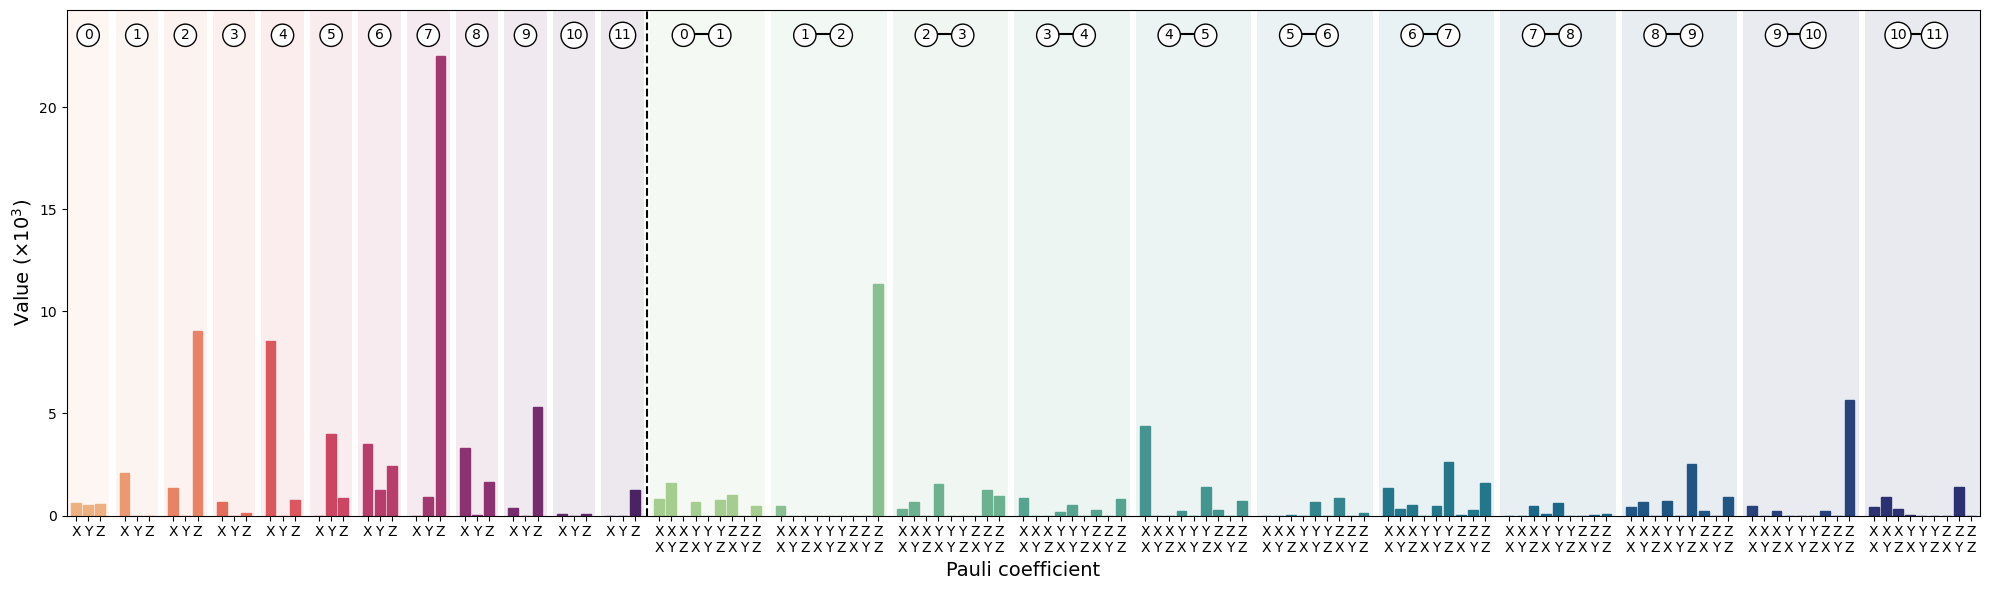

In [44]:
import matplotlib as mpl
import seaborn as sns
import matplotlib.pylab as plt

def plot_spl_coefficients(spl_noise_dict: dict, num_qubits, 
                          figsize = (20, 6), dx = 0.25, alpha = 0.1,
                          rescale_factor = 1e3, labelfontsize = 14,
                          filename = None):
    """
    Plots the coefficients of a Sparse Pauli Lindblad noise in a histogram.

    Args
    -----------
    spl_noise_dict (dict):  dictonary with pauli strings being the keys, and the values being the respective coefficients.
    num_qubits (int):       number of qubits to consider in the SPL noise. If less then the number of qubits in the spl_noise_dict, will
                            select only those Pauli strings and coefficients belonging to qubits [0,..., num_qubits -1]
    dx (float):             width of the colored backround below the histogram. If dx=0, the whole area in the plot will be coloured.
    alpha (float):          transparency of the coloured backround below the histogram bars.
    rescale_factor (float): rescale the coefficients by multiplying them by rescale_factor, and specify it on the y-axis.
    labelfontsize (int):    font size for the x- and y- axes.
    filename (str):         if provided, will save the image in PDF format with this name. 

    Returns
    --------------
    the plot of the SPL coefficients.
    
    """

    def discretize_colormap(cmap, num_colors):
        """
        Given a colormap, outputs a discretized version of the colormap as a list of colors.
        """    
        cmap = [cmap(i) for i in range(cmap.N)]   
        cmap = mpl.colors.LinearSegmentedColormap.from_list('Custom cmap', cmap, num_colors) 
        cmap_list = [cmap(i) for i in range(cmap.N)]
        return cmap_list
    
    ################################
    # EXTRACTING SPL COEFFICIENTS
    ################################
    
    # Create a list to contain Pauli strings in specific order (first single-qubit temrs in lexicographical order, then two-qubit in lexicographical order)
    paulis = np.array([['I',] * num_qubits,] * (3 * num_qubits + 9 * (num_qubits - 1)))

    # Create ordered single-qubit terms
    for q in range(num_qubits):
        paulis[3 * q + 0][q] = 'X'
        paulis[3 * q + 1][q] = 'Y'
        paulis[3 * q + 2][q] = 'Z'

    # Create ordered two-qubit terms
    for q in range(num_qubits - 1):
        paulis[3*num_qubits + 9*q + 0][q:q+2] = ['X', 'X']
        paulis[3*num_qubits + 9*q + 1][q:q+2] = ['X', 'Y']
        paulis[3*num_qubits + 9*q + 2][q:q+2] = ['X', 'Z']
        paulis[3*num_qubits + 9*q + 3][q:q+2] = ['Y', 'X']
        paulis[3*num_qubits + 9*q + 4][q:q+2] = ['Y', 'Y']
        paulis[3*num_qubits + 9*q + 5][q:q+2] = ['Y', 'Z']
        paulis[3*num_qubits + 9*q + 6][q:q+2] = ['Z', 'X']
        paulis[3*num_qubits + 9*q + 7][q:q+2] = ['Z', 'Y']
        paulis[3*num_qubits + 9*q + 8][q:q+2] = ['Z', 'Z']

    # Join lists to create Pauli strings
    paulis = [''.join(p) for p in paulis.tolist()]

    # Select values in the provided dictionary and reorders them according to the standard ordering defined above
    max_num_qubits = len(list(spl_noise_dict.keys())[0])

    # If num_qubits < tot qubits in the SPL dictionary, add identities in the keys to ignore undesired qubits
    trivial_qubits = 'I'*(max_num_qubits - num_qubits)
    
    spl_dict = {}
    for p_str in paulis: 
        try:
            spl_dict[p_str] = spl_coeffs[p_str + trivial_qubits]
        except KeyError: # If Pauli string is absent, assume corresponding coefficient is 0
            spl_dict[p_str] = 0    
    spl_values = list(spl_dict.values())

    # For plotting purposes, add empty places in the list to separate coefficients belonging to different qubits 
    [spl_values.insert(3 * q + _, 0) for _, q in enumerate(range(1, num_qubits + 1))]

    # For plotting purposes, add empty places in the list to separate coefficients belonging to different pairs of qubits 
    [spl_values.insert(4 * num_qubits + 9 * q + _, 0) for _, q in enumerate(range(1, num_qubits + 1))]
    print(spl_values)

    # Labels in the histogram including empty spaces
    labels = ['X', 'Y', 'Z', ''] * num_qubits + ['X\nX', 'X\nY', 'X\nZ', 'Y\nX', 'Y\nY', 'Y\nZ', 'Z\nX', 'Z\nY', 'Z\nZ', ''] * (num_qubits-1)
    # Actual labels in the histogram
    labels2 = ['X', 'Y', 'Z'] * num_qubits + ['X\nX', 'X\nY', 'X\nZ', 'Y\nX', 'Y\nY', 'Y\nZ', 'Z\nX', 'Z\nY', 'Z\nZ'] * (num_qubits-1)

    # Get indices at which the labels are nontrivial (i.e. contain empty data)
    non_trivial_idx = np.where(np.array(labels) != '')[0]
    # Indices for single-qubit terms
    single_qubit_idx = np.array_split(non_trivial_idx[:3*num_qubits], num_qubits)
    # Indices for two-qubit terms
    two_qubit_idx = np.array_split(non_trivial_idx[3*num_qubits:], num_qubits-1)

    #######################
    # PLOTTING HISTOGRAM
    #######################
    if num_qubits < 11:
        cmap_1qubit = sns.color_palette("deep", as_cmap=True)
        cmap_2qubit = sns.color_palette("colorblind", as_cmap=True)
    else:
        cmap_1qubit = discretize_colormap(sns.color_palette("flare", as_cmap=True), num_qubits)
        cmap_2qubit = discretize_colormap(sns.color_palette("crest", as_cmap=True), num_qubits-1)

    fig = plt.figure(figsize=figsize)
    
    # Histogram plot
    spl_values = rescale_factor * np.array(spl_values)
    bars = plt.bar(range(len(spl_values)), spl_values, align='center')

    # ylim of the plot
    ymax =  max(spl_values) + 0.1 * max(spl_values)
    plt.ylim(0, ymax)

    plt.xlim(-1 + dx, len(labels)- 1 - dx)

    # Height at which to draw the annotations for the number of qubits
    y_qubs_annotations = ymax - 0.05 * ymax

    # Set the xticks labels to be the Pauli strings
    plt.xticks(np.where(np.array(labels) != '')[0], labels=labels2)

    # SINGLE-QUBIT TERMS
    # Change colors to the histogram
    for i, sq in enumerate(single_qubit_idx):
        [bars[q].set_color(cmap_1qubit[i]) for q in sq]

    # Add background shading in the corresponding area
    for q in range(num_qubits):
        plt.axvspan(-1 + 4 * q + dx, -1 + 4 * (q + 1) - dx, facecolor=cmap_1qubit[q], alpha=alpha, zorder=0)

    # Add annotation for the number of qubits
    for q in range(num_qubits):
        plt.annotate(f"{q}", (1 + 4 * q, y_qubs_annotations), bbox={"boxstyle" : "circle", "facecolor":"white", "edgecolor":"black"}, ha='center', va='center')

    plt.vlines(4 * num_qubits - 1, 0, ymax, ls="--", color='black')

    # TWO-QUBIT TERMS
    # Change colors to the histogram
    for i, sq in enumerate(two_qubit_idx):
        [bars[q].set_color(cmap_2qubit[i]) for q in sq]

    # Add background shading in the corresponding area
    for q in range(num_qubits-1):
        plt.axvspan(4 * num_qubits + 10 * q - 1 + dx, 4 * num_qubits + 10 * (q + 1) - 1 - dx, facecolor=cmap_2qubit[q], alpha=alpha, zorder=0)
    
    # Add annotation for the number of qubits
    for q in range(num_qubits-1):
        plt.annotate(f"{q+0}", (4 * num_qubits + 10 * q + 2, y_qubs_annotations), bbox={"boxstyle" : "circle", "facecolor":"white", "edgecolor":"black"}, ha='center', va='center')
        plt.annotate(f"{q+1}", (4 * num_qubits + 10 * q + 5, y_qubs_annotations), bbox={"boxstyle" : "circle", "facecolor":"white", "edgecolor":"black"}, ha='center', va='center')
        plt.plot([4 * num_qubits + 10 * q + 2, 4 * num_qubits + 10 * q + 5], [y_qubs_annotations + ymax*0.002, y_qubs_annotations + ymax*0.002], c = 'black')

    plt.xlabel("Pauli coefficient", fontsize=14)
    
    if rescale_factor != 1:
        exp = int(np.log10(rescale_factor))
        plt.ylabel(rf"Value ($\times 10^{exp}$)", fontsize=labelfontsize)
    else: 
        plt.ylabel("Value", fontsize=labelfontsize)

    plt.tight_layout()

    if isinstance(filename, str):
        plt.savefig(filename + ".pdf", format="pdf")

plot_spl_coefficients(spl_coeffs, 12, rescale_factor=1e3, filename='SPL')